In [1]:
%load_ext autoreload
%autoreload 2
from mg_sampling import PROJECT_DIR
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ast import literal_eval
import itertools

from mg_sampling.tools import bayesian_bootstrap

### Coordination

In [2]:
# Replex
systems = ['7ez0']
forcefields = ['mMg_tip3p']
replicates = [0]
repids = [0, 7]
ions = ['MG']

df = pd.DataFrame()
for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'replicate{replicate}' / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'{ion}_OW_motifs.csv', na_filter=False, usecols=['time', 'index', 'n_inner', 'mgrna'])
    _df['system'] = system
    _df['forcefield'] = forcefield
    _df['repid'] = int(repid)
    _df['replicate'] = replicate
    _df['method'] = 'replex'
    df = pd.concat([df, _df])

# PlainMD
systems = ['7ez0']
forcefields = ['mMg_tip3p', 'nMg_tip3p']
replicates = range(8)
ions = ['MG']

for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    try:
        path = PROJECT_DIR / 'plain_md' / system / forcefield / f'rep{replicate:02d}'
        _df = pd.read_csv(path / f'{ion}_OW_motifs.csv', na_filter=False, usecols=['time', 'index', 'n_inner', 'mgrna'])
        _df['system'] = system
        _df['forcefield'] = forcefield
        _df['replicate'] = replicate
        _df['method'] = 'plain_md'
        df = pd.concat([df, _df])
    except FileNotFoundError as e:
        print(e)
        pass

for col in ['mgrna', 'forcefield', 'system', 'method']:
    df[col] = df[col].astype('category')

In [3]:
df['repid'] = df['repid'].fillna(0).astype(int)
df['sim'] = df['method'].str.cat(df['forcefield'], sep='_').str.cat(df['repid'].astype(str), sep='_')
df['sim'] = df['sim'].map({
    'replex_mMg_tip3p_0': 'μMg (REx, $λ_0$)',
    'replex_mMg_tip3p_7': 'μMg (REx, $λ_7$)',
    'plain_md_mMg_tip3p_0': 'μMg (MD)',
    'plain_md_nMg_tip3p_0': 'nMg (MD)',
})

In [8]:
df.head()

,time,index,n_inner,mgrna,system,forcefield,repid,replicate,method,sim
0,0.0,12442,6,6Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
1,0.0,12443,6,2Oph4Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
2,0.0,12444,6,Oph5Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
3,0.0,12445,6,4Oph2Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
4,0.0,12446,6,3Oph3Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"


In [ ]:
palette = ['tomato', 'darkred', 'gray', 'mediumpurple']
labels = ['μMg (REx, $λ_0$)', 'μMg (REx, $λ_7$)', 'μMg (MD)', 'nMg (MD)']

tstart_replex = 50000  # ps
tstart_plain_md = 150000
grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})")

sns.set_style("ticks", {'axes.grid': True})



[((np.int64(6), 'nMg (MD)', np.int64(0)),
  time      n_inner  sim       replicate
  150000.0  6        nMg (MD)  0            354
  151000.0  6        nMg (MD)  0            354
  152000.0  6        nMg (MD)  0            356
  153000.0  6        nMg (MD)  0            356
  154000.0  6        nMg (MD)  0            356
                                           ... 
  596000.0  6        nMg (MD)  0            354
  597000.0  6        nMg (MD)  0            354
  598000.0  6        nMg (MD)  0            356
  599000.0  6        nMg (MD)  0            354
  600000.0  6        nMg (MD)  0            352
  Length: 451, dtype: int64),
 ((np.int64(6), 'nMg (MD)', np.int64(1)),
  time      n_inner  sim       replicate
  150000.0  6        nMg (MD)  1            356
  151000.0  6        nMg (MD)  1            352
  152000.0  6        nMg (MD)  1            354
  153000.0  6        nMg (MD)  1            354
  154000.0  6        nMg (MD)  1            352
                                    

KeyError: 'time'

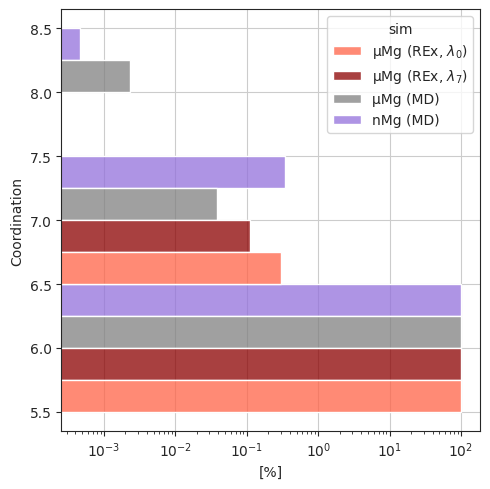

In [24]:
palette = ['tomato', 'darkred', 'gray', 'mediumpurple']
labels = ['μMg (REx, $λ_0$)', 'μMg (REx, $λ_7$)', 'μMg (MD)', 'nMg (MD)']

tstart_replex = 50000  # ps
tstart_plain_md = 150000
grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})")

sns.set_style("ticks", {'axes.grid': True})

ax = sns.histplot(grouped,
    y='n_inner',
    hue='sim',
    hue_order=labels,
    palette=palette,
    stat='percent',
    discrete=True,
    multiple='dodge',
    common_norm=False,
)

# ax.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
ax.set_xscale('log')
ax.set_xlabel("[%]")
ax.set_ylabel(r"Coordination")
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/average_n_inner.pdf', bbox_inches='tight')

### Inner-bound (< 2.8 Å)

In [149]:
# Replex
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p']
replicates = [0]
repids = [0]
ions = ['MG', 'NA']

df = []
for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'replicate{replicate}' / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'{ion}_motifs.csv', na_filter=False)
    _df = _df.loc[_df['time'] % 1000.0 == 0]
    _df['system'] = system
    _df['forcefield'] = forcefield
    _df['repid'] = repid
    _df['replicate'] = replicate
    _df['method'] = 'replex'
    df.append(_df)

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['nMg_tip3p_hard', 'mMg_tip3p_hard', 'nMg_tip3p']
replicates = range(8)
ions = ['MG', 'NA']

for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    try:
        path = PROJECT_DIR / 'plain_md' / system / forcefield / f'rep{replicate:02d}'
        _df = pd.read_csv(path / f'{ion}_motifs.csv', na_filter=False)
        _df = _df.loc[_df['time'] % 1000.0 == 0]
        _df['system'] = system
        _df['forcefield'] = forcefield
        _df['replicate'] = replicate
        _df['method'] = 'plain_md'
        df.append(_df)
    except FileNotFoundError as e:
        print(e)
        pass

df = pd.concat(df)
for col in ['name', 'mgrna', 'forcefield', 'system', 'method']:
    df[col] = df[col].astype('category')


In [150]:
tstart_replex = 50000  # ps
tstart_plain_md = 150000

grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})").groupby(
    ['time', 'name', 'n_inner', 'forcefield', 'system', 'replicate', 'method'], observed=True
    ).size().reset_index(name='counts')

In [151]:
# Compute unbound by taking the complement
n_tot = {'MG': 178, 'NA': 121}
tot = grouped.groupby(['time', 'name', 'forcefield', 'system', 'replicate', 'method'], observed=True).sum()['counts'].reset_index()
tot['tot'] = tot['name'].map(n_tot).astype(int)
tot['counts'] = tot['tot'] - tot['counts']
tot = tot.drop(columns='tot')
tot.insert(2, 'n_inner', -1)
grouped = pd.concat([grouped, tot])
grouped['sim'] = grouped['method'].str.cat(grouped['forcefield'], sep='_')
grouped['sim'] = grouped['sim'].map({
    'replex_mMg_tip3p': 'μMg (REx)',
    'plain_md_mMg_tip3p_hard': 'μMg (MD)',
    'plain_md_nMg_tip3p_hard': 'nMg (MD)',
    'plain_md_nMg_tip3p': 'nMg (MD-soft)',
})
grouped['binding'] = grouped['n_inner'].replace(-1, 'Bulk').replace(0, 'Outer')
grouped = grouped.sort_values('n_inner')

In [154]:
grouped.query("forcefield == 'nMg_tip3p'")

,time,name,n_inner,forcefield,system,replicate,method,counts,sim,binding


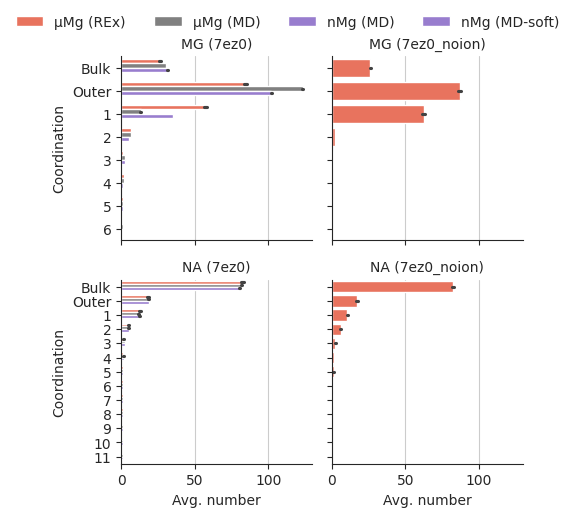

In [152]:
palette = ['tomato', 'gray', 'mediumpurple', 'mediumpurple']
labels = ['μMg (REx)', 'μMg (MD)', 'nMg (MD)', 'nMg (MD-soft)']

g = sns.FacetGrid(grouped, row='name', col='system', sharey='row')
sns.set_style("ticks", {'axes.grid': True})

g.map_dataframe(
    sns.barplot,
    y='binding',
    x='counts',
    orient='h',
    hue='sim',
    hue_order=labels,
    palette=palette,
)

g.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
g.set_xlabels("Avg. number")
g.set_ylabels(r"Coordination")
g.set_titles("{row_name} ({col_name})")
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/average_coordination.pdf', bbox_inches='tight')

## Inner-bound sites

In [119]:
tstart_replex = 50000  # ps
tstart_plain_md = 150000

grouped = df.query(f"((method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})) and n_inner > 0").copy()
grouped['inner_names'] = grouped['inner_names'].map(literal_eval)

In [120]:
grouped = grouped.explode('inner_names')

In [121]:
# Count by name
grouped = grouped.groupby(['name', 'system', 'method', 'forcefield', 'inner_names'], observed=True).size()


In [124]:
grouped.groupby(['name', 'system', 'method', 'forcefield'], observed=True).sum()

name  system      method    forcefield    
MG    7ez0        plain_md  mMg_tip3p_hard    126433
                            nMg_tip3p_hard    211153
                  replex    mMg_tip3p          12377
      7ez0_noion  replex    mMg_tip3p          10230
NA    7ez0        plain_md  mMg_tip3p_hard    110244
                            nMg_tip3p_hard    140899
                  replex    mMg_tip3p           4912
      7ez0_noion  replex    mMg_tip3p           5909
dtype: int64

In [128]:
grouped = (grouped / grouped.groupby(['name', 'system', 'method', 'forcefield'], observed=True).sum())

In [132]:
grouped = grouped.reset_index(name='proportion')

In [133]:
grouped

,name,system,method,forcefield,inner_names,proportion
0,MG,7ez0,plain_md,mMg_tip3p_hard,C2,0.000032
1,MG,7ez0,plain_md,mMg_tip3p_hard,H3',0.000103
2,MG,7ez0,plain_md,mMg_tip3p_hard,H4',0.000008
3,MG,7ez0,plain_md,mMg_tip3p_hard,H5'1,0.000040
4,MG,7ez0,plain_md,mMg_tip3p_hard,H5'2,0.000340
...,...,...,...,...,...,...
195,NA,7ez0_noion,replex,mMg_tip3p,O4,0.028939
196,NA,7ez0_noion,replex,mMg_tip3p,O4',0.001354
197,NA,7ez0_noion,replex,mMg_tip3p,O5',0.028431
198,NA,7ez0_noion,replex,mMg_tip3p,O6,0.028600


array(['O2P', 'O1P', 'N7', "O2'", 'O6', 'O4', "HO'2", "O3'", 'O2', "O5'",
       'CL', 'N3', 'N1', "H5'2", "H1'", "O4'", 'H62', 'H61', 'H8', 'H22',
       "H3'", 'H42', 'H3', 'P', 'C8', 'N6', "H5'1", "H4'", "H2'1", 'C6',
       'N4', 'H2', 'H41', 'H5', 'H1', 'N2', 'H21', 'H5T', 'C5', 'C2',
       "C2'", "C4'", 'C4', 'H3T', 'H6', "C5'", "C1'"], dtype=object)

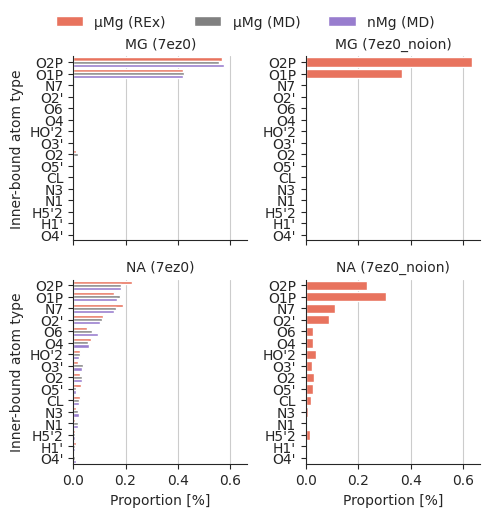

In [ ]:
grouped['sim'] = grouped['method'].str.cat(grouped['forcefield'], sep='_')
grouped['sim'] = grouped['sim'].map({
    'replex_mMg_tip3p': 'μMg (REx)',
    'plain_md_mMg_tip3p_hard': 'μMg (MD)',
    'plain_md_nMg_tip3p_hard': 'nMg (MD)',
})
palette = ['tomato', 'gray', 'mediumpurple']
labels = ['μMg (REx)', 'μMg (MD)', 'nMg (MD)']

g = sns.FacetGrid(grouped, row='name', col='system', sharey='row')
sns.set_style("ticks", {'axes.grid': True})

g.map_dataframe(
    sns.barplot,
    y='inner_names',
    x='proportion',
    orient='h',
    hue='sim',
    hue_order=labels,
    palette=palette,
    order=grouped[grouped['proportion'] > 0.01].sort_values('proportion', ascending=False)['inner_names'].unique(),
)

g.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
g.set_xlabels("Proportion")
g.set_ylabels("Inner-bound atom type")
g.set_titles("{row_name} ({col_name})")
for axis in g.axes.flat:
    axis.tick_params(labelleft=True)
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/binding_sites.pdf', bbox_inches='tight')

### Summarize motifs